In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_csv(r'..\data\raw\hr_employee_attrition.csv')
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 1]

if missing_values.empty:
    print('No missing values found.')
else:
    display(missing_values.sort_values(ascending=False))

No missing values found.


In [5]:
display(df.nunique())

# EmployeeCount,EmployeeNumber,Over18,StandardHours

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [6]:
print(df.duplicated().sum())

0


In [7]:
ordered_columns = [
    # Personal
    'Age', 'Gender', 'MaritalStatus', 'Education', 'EducationField', 'DistanceFromHome',

    # Job Context
    'Department', 'JobRole', 'JobLevel', 'BusinessTravel', 'OverTime',

    # Financial
    'MonthlyIncome', 'DailyRate', 'HourlyRate', 'MonthlyRate', 'PercentSalaryHike', 'StockOptionLevel',

    # Work Experience & Tenure
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'NumCompaniesWorked',

    # Performance & Satisfaction
    'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating', 'TrainingTimesLastYear',

    # Label
    'Attrition'
]

df = df[ordered_columns]
display(df.head())
print(f'Shapr after column selection: {df.shape}')

,Age,Gender,MaritalStatus,Education,EducationField,DistanceFromHome,Department,JobRole,JobLevel,BusinessTravel,...,YearsWithCurrManager,NumCompaniesWorked,EnvironmentSatisfaction,JobSatisfaction,RelationshipSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,TrainingTimesLastYear,Attrition
0,41,Female,Single,2,Life Sciences,1,Sales,Sales Executive,2,Travel_Rarely,...,5,8,2,4,1,1,3,3,0,Yes
1,49,Male,Married,1,Life Sciences,8,Research & Development,Research Scientist,2,Travel_Frequently,...,7,1,3,2,4,3,2,4,3,No
2,37,Male,Single,2,Other,2,Research & Development,Laboratory Technician,1,Travel_Rarely,...,0,6,4,3,2,3,2,3,3,Yes
3,33,Female,Married,4,Life Sciences,3,Research & Development,Research Scientist,1,Travel_Frequently,...,0,1,4,3,3,3,3,3,3,No
4,27,Male,Married,1,Medical,2,Research & Development,Laboratory Technician,1,Travel_Rarely,...,2,9,1,2,4,3,3,3,3,No


Shapr after column selection: (1470, 31)


In [8]:
continuous_columns = [
    'Age', 'DistanceFromHome', 'MonthlyIncome', 'DailyRate', 'HourlyRate',
    'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager',
]

discrete_columns = [
    'NumCompaniesWorked', 'TrainingTimesLastYear'
]

numerical_columns = continuous_columns + discrete_columns

nominal_columns = [
    'Gender', 'MaritalStatus', 'EducationField', 'Department', 'JobRole',
    'BusinessTravel', 'OverTime'
]

ordinal_columns = [
    'Education', 'JobLevel', 'StockOptionLevel', 'EnvironmentSatisfaction',
    'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance', 'JobInvolvement',
    'PerformanceRating'
]

categorical_columns = nominal_columns + ordinal_columns

label = ['Attrition']

In [9]:
display(df[numerical_columns + ordinal_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
MonthlyRate,1470.0,14313.103401,7117.786044,2094.0,8047.0,14235.5,20461.50,26999.0
PercentSalaryHike,1470.0,15.209524,3.659938,11.0,12.0,14.0,18.00,25.0
TotalWorkingYears,1470.0,11.279592,7.780782,0.0,6.0,10.0,15.00,40.0
YearsAtCompany,1470.0,7.008163,6.126525,0.0,3.0,5.0,9.00,40.0
YearsInCurrentRole,1470.0,4.229252,3.623137,0.0,2.0,3.0,7.00,18.0


In [10]:
checks = {
    'Age < TotalWorkingYears':
        df['Age'] < df['TotalWorkingYears'],

    'TotalWorkingYears < YearsAtCompany':
        df['TotalWorkingYears'] < df['YearsAtCompany'],

    'YearsAtCompany < YearsInCurrentRole':
        df['YearsAtCompany'] < df['YearsInCurrentRole'],

    'YearsAtCompany < YearsWithCurrManager':
        df['YearsAtCompany'] < df['YearsWithCurrManager']
}

for name, condition in checks.items():
    print(f'{name}: {condition.sum()}')

Age < TotalWorkingYears: 0
TotalWorkingYears < YearsAtCompany: 0
YearsAtCompany < YearsInCurrentRole: 0
YearsAtCompany < YearsWithCurrManager: 0


In [11]:
outlier_summary = {}

for column in continuous_columns:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        continue

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    mask = (~values.between(lower_limit, upper_limit))
    outliers_count = mask.sum()

    if outliers_count > 0:
        outlier_summary[column] = (lower_limit, upper_limit)

        percentage = 100 * outliers_count / len(values)

        print(f'{column:25s} -> 'f'{outliers_count} outliers ({percentage:.2f}%)')

MonthlyIncome             -> 114 outliers (7.76%)
TotalWorkingYears         -> 63 outliers (4.29%)
YearsAtCompany            -> 104 outliers (7.07%)
YearsInCurrentRole        -> 21 outliers (1.43%)
YearsSinceLastPromotion   -> 107 outliers (7.28%)
YearsWithCurrManager      -> 14 outliers (0.95%)


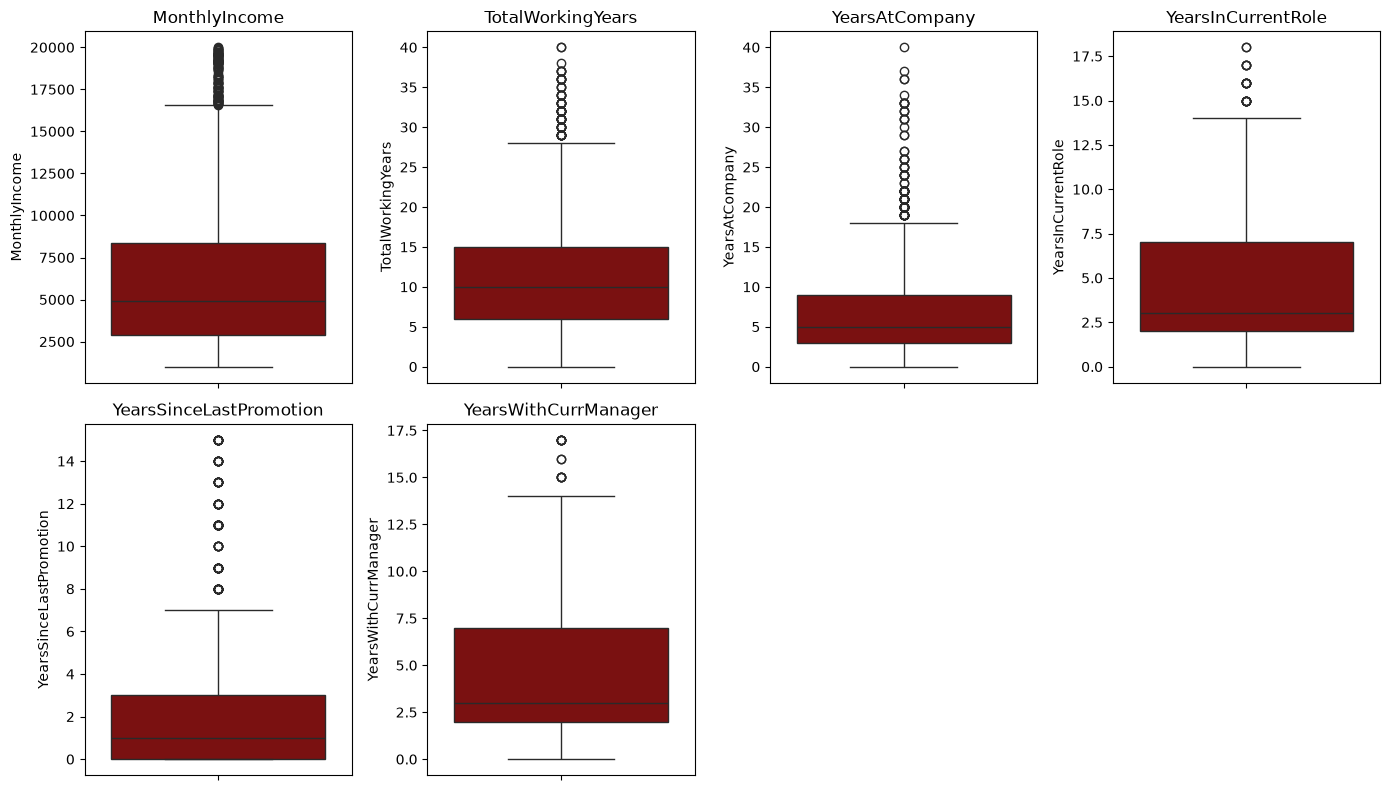

In [12]:
columns = list(outlier_summary.keys())

if len(columns) > 0:
    n_columns = 4
    n_rows = math.ceil(len(columns) / n_columns)

    figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

    if len(columns) == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, column in enumerate(columns):
        sns.boxplot(data=df, y=column, ax=axes[i], color='darkred')
        axes[i].set_title(column)

    for j in range(len(columns), len(axes)):
        figure.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

else:
    print("No outliers found.")

In [13]:
skewness_values = df[continuous_columns].skew()

skewed_columns = skewness_values[skewness_values.abs() > 1].sort_values(key=abs, ascending=False)

for column, skewness in skewed_columns.items():
    print(f'{column:25s} -> {skewness:.3f}')

YearsSinceLastPromotion   -> 1.984
YearsAtCompany            -> 1.765
MonthlyIncome             -> 1.370
TotalWorkingYears         -> 1.117


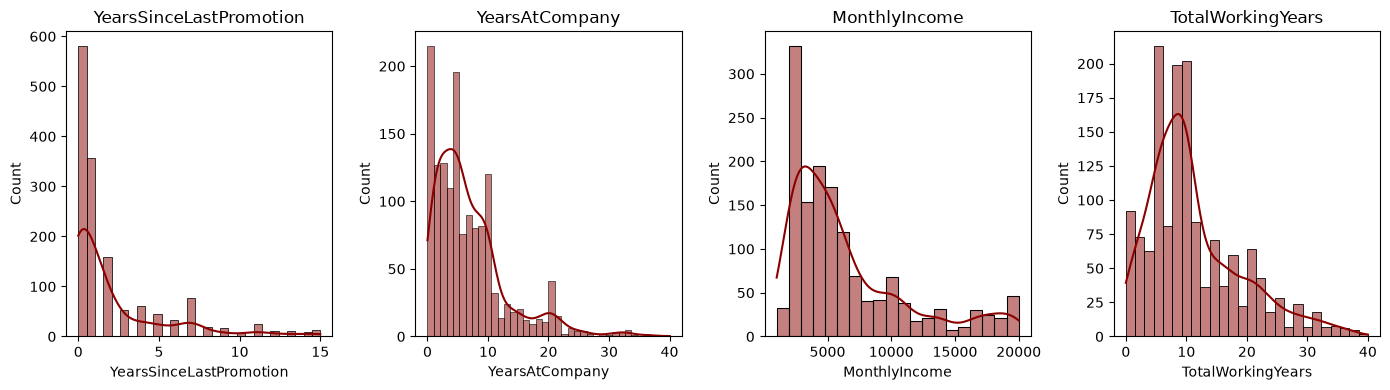

In [14]:
columns = skewed_columns.index.tolist()

if len(columns) > 0:
    n_columns = 4
    n_rows = math.ceil(len(columns) / n_columns)

    figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

    if len(columns) == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, column in enumerate(columns):
        sns.histplot(df, x=column, ax=axes[i], color='darkred', kde=True)
        axes[i].set_title(column)

    for j in range(len(columns), len(axes)):
        figure.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

else:
    print("No skewed columns found.")

In [15]:
print("Original MonthlyIncome Skewness:",
      df['MonthlyIncome'].skew())

print("Log-transformed MonthlyIncome Skewness:",
      np.log1p(df['MonthlyIncome']).skew())

Original MonthlyIncome Skewness: 1.3698166808390662
Log-transformed MonthlyIncome Skewness: 0.2864483763069351


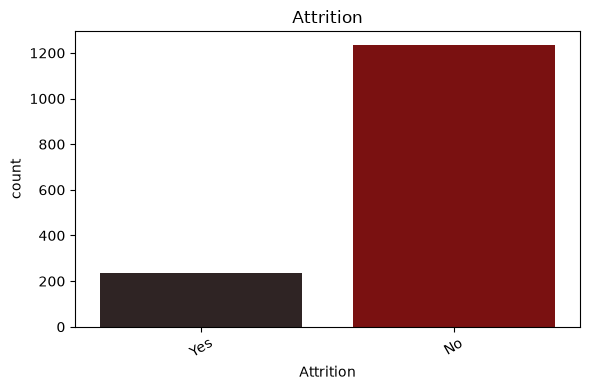

In [16]:
target_column = 'Attrition'

figure, axes = plt.subplots(figsize=(6, 4))

sns.countplot(data=df, x=target_column, ax=axes, hue=target_column, palette='dark:darkred', legend=False)
axes.set_title(target_column)
axes.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# There is high class imbalance, so we will use class weights in the model.

In [18]:
df['Attrition_Encoded'] = df['Attrition'].map({'No' : 0,'Yes': 1})

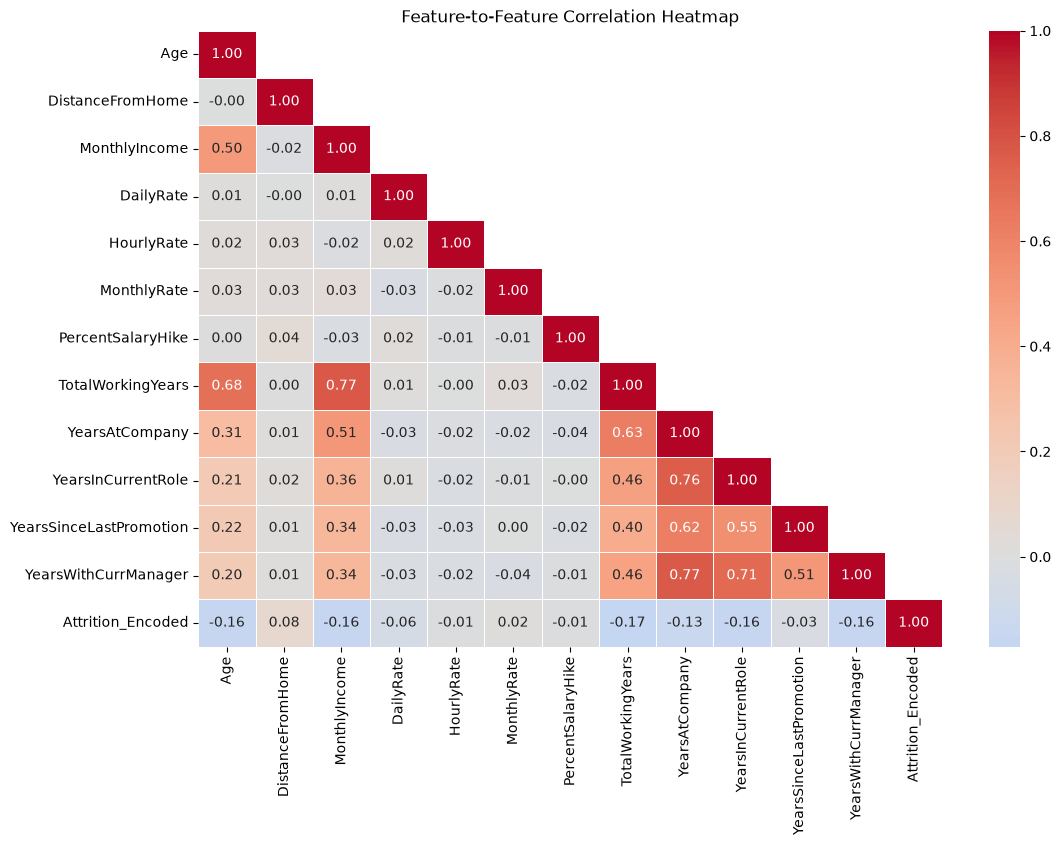

In [19]:
plt.figure(figsize=(12, 8))
corr = df[[*continuous_columns,'Attrition_Encoded']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0,mask=np.triu(np.ones_like(corr, bool), 1))
plt.title('Feature-to-Feature Correlation Heatmap')
plt.show()

In [20]:
from scipy.stats import chi2_contingency

chi2_results = []

for column in categorical_columns:
    contingency_table = pd.crosstab(df[column], df['Attrition'])
    
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    
    chi2_results.append({
        'Feature': column,
        'Chi2 Statistic': round(chi2, 4),
        'p-value': round(p, 5),
        'Significant (p < 0.05)': p < 0.05,
        "Cramér's V": round(cramers_v, 4)
       
    })

chi2_df = pd.DataFrame(chi2_results).sort_values(by="Cramér's V", ascending=False)
display(chi2_df)

,Feature,Chi2 Statistic,p-value,Significant (p < 0.05),Cramér's V
6,OverTime,87.5643,0.00000,True,0.2441
4,JobRole,86.1903,0.00000,True,0.2421
8,JobLevel,72.5290,0.00000,True,0.2221
9,StockOptionLevel,60.5983,0.00000,True,0.2030
1,MaritalStatus,46.1637,0.00000,True,0.1772
14,JobInvolvement,28.4920,0.00000,True,0.1392
5,BusinessTravel,24.1824,0.00001,True,0.1283
10,EnvironmentSatisfaction,22.5039,0.00005,True,0.1237
11,JobSatisfaction,17.5051,0.00056,True,0.1091
13,WorkLifeBalance,16.3251,0.00097,True,0.1054


In [21]:
X = df[continuous_columns + discrete_columns + categorical_columns]
y = df['Attrition_Encoded']

In [22]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test= train_test_split(X,y,train_size=0.8,random_state=42,stratify=y)

In [23]:
import warnings
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

warnings.filterwarnings('ignore', category=FutureWarning)

In [24]:
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)

        q1 = np.percentile(X, 25, axis=0)
        q3 = np.percentile(X, 75, axis=0)
        iqr = q3 - q1

        self.lower_ = q1 - self.k * iqr
        self.upper_ = q3 + self.k * iqr

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)

In [25]:
def add_features(df):
    df = df.copy()

    # Income relative to job level
    df['IncomePerJobLevel'] = (
        df['MonthlyIncome'] / df['JobLevel'].clip(lower=1)
    )

    # Company tenure relative to total work experience
    df['TenureRatio'] = (
        df['YearsAtCompany'] /
        df['TotalWorkingYears'].replace(0, 1)
    )

    # Time since last promotion relative to company tenure
    df['PromotionGapRatio'] = (
        df['YearsSinceLastPromotion'] /
        df['YearsAtCompany'].replace(0, 1)
    )

    satisfaction_columns = [
        'EnvironmentSatisfaction',
        'JobSatisfaction',
        'RelationshipSatisfaction',
        'WorkLifeBalance',
        'JobInvolvement'
    ]

    # Average satisfaction and involvement
    df['SatisfactionMean'] = df[satisfaction_columns].mean(axis=1)

    # Number of low satisfaction/involvement scores
    df['LowSatisfactionCnt'] = (
        df[satisfaction_columns] <= 2
    ).sum(axis=1)

    return df


X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

In [26]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['precision', 'recall', 'f1', 'roc_auc']


def run_experiment(preprocessor, experiment_name, X=None):
    if X is None:
        X = X_train

    pipelines = {
        'Logistic Regression': Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', LogisticRegression(
                class_weight='balanced', random_state=42
            ))
        ]),
        'SVC': Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', SVC(
                class_weight='balanced',
                probability=True,
                random_state=42
            ))
        ])
    }

    results = {}

    for model_name, pipeline in pipelines.items():
        scores = cross_validate(
            pipeline, X, y_train,
            cv=skf, scoring=scoring
        )

        results[model_name] = scores

        print(f"\n--- {model_name} ({experiment_name}) ---")
        for metric in scoring:
            print(
                f"Mean {metric}: "
                f"{np.mean(scores[f'test_{metric}']):.4f}"
            )

        pipeline.fit(X, y_train)

    print("\nDone fitting both pipelines on training data!")
    return results, pipelines

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False),nominal_columns),
        ('num', StandardScaler(), numerical_columns + ordinal_columns)
    ]
)

In [28]:
log_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False),nominal_columns),

        ('income', Pipeline([('log', FunctionTransformer(np.log1p)),('scaler', StandardScaler())]), ['MonthlyIncome']),

        ('num', StandardScaler(),[col for col in numerical_columns + ordinal_columns
          if col != 'MonthlyIncome'])
    ]
)

In [29]:
log2_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False),nominal_columns),

        ('income', Pipeline([('log', FunctionTransformer(np.log1p)),('scaler', StandardScaler())]), ['YearsSinceLastPromotion']),

        ('num', StandardScaler(),[col for col in numerical_columns + ordinal_columns
          if col != 'MonthlyIncome'])
    ]
)

In [30]:
log3_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False),nominal_columns),

        ('income', Pipeline([('log', FunctionTransformer(np.log1p)),('scaler', StandardScaler())]), ['TotalWorkingYears']),

        ('num', StandardScaler(),[col for col in numerical_columns + ordinal_columns
          if col != 'MonthlyIncome'])
    ]
)

In [31]:
outlier_preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', Pipeline([
            ('outlier_cap', Winsorizer(k=1.5)),
            ('scaler', StandardScaler())
        ]), continuous_columns),

        ('discrete', StandardScaler(), discrete_columns),

        ('ordinal', StandardScaler(), ordinal_columns),

        ('nominal', OneHotEncoder(
            drop='first',
            sparse_output=False
        ), nominal_columns)
    ]
)

In [32]:
engineered_continuous = [
    'IncomePerJobLevel',
    'TenureRatio',
    'PromotionGapRatio',
    'SatisfactionMean'
]

engineered_discrete = ['LowSatisfactionCnt']

continuous_columns_fe = continuous_columns + engineered_continuous
discrete_columns_fe = discrete_columns + engineered_discrete

feature_preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', Pipeline([
            ('outlier_cap', Winsorizer(k=1.5)),
            ('scaler', StandardScaler())
        ]), continuous_columns_fe),

        ('discrete', StandardScaler(), discrete_columns_fe),

        ('ordinal', StandardScaler(), ordinal_columns),

        ('nominal', OneHotEncoder(
            drop='first',
            sparse_output=False
        ), nominal_columns)
    ]
)

In [33]:
feature_only_preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), continuous_columns_fe),
        ('discrete', StandardScaler(), discrete_columns_fe),
        ('ordinal', StandardScaler(), ordinal_columns),
        ('nominal', OneHotEncoder(drop='first', sparse_output=False), nominal_columns)
    ]
)

In [34]:
baseline_resulte, baseline_pipelines = run_experiment(preprocessor,'Base Line')
# log_resuls, log_pipelines = run_experiment(log_preprocessor,'Log1p MonthlyIncome')
# log2_resuls, log2_pipelines = run_experiment(log2_preprocessor,'Log1p YearsSinceLastPromotion')
# log3_resuls, log3_pipelines = run_experiment(log3_preprocessor,'Log1p TotalWorkingYears')
outlier_results, outlier_pipelines = run_experiment(outlier_preprocessor,"Outlier Treatment")
# feature_results, feature_pipelines = run_experiment(feature_preprocessor,"Feature Engineering",X=X_train_fe)
# feature_only_results, feature_only_pipelines = run_experiment(feature_only_preprocessor,"Feature Engineering Only",X=X_train_fe)


--- Logistic Regression (Base Line) ---
Mean precision: 0.3640
Mean recall: 0.7316
Mean f1: 0.4848
Mean roc_auc: 0.8268

--- SVC (Base Line) ---
Mean precision: 0.4990
Mean recall: 0.5947
Mean f1: 0.5411
Mean roc_auc: 0.8116

Done fitting both pipelines on training data!

--- Logistic Regression (Outlier Treatment) ---
Mean precision: 0.3819
Mean recall: 0.7421
Mean f1: 0.5032
Mean roc_auc: 0.8273

--- SVC (Outlier Treatment) ---
Mean precision: 0.4992
Mean recall: 0.6000
Mean f1: 0.5435
Mean roc_auc: 0.8129

Done fitting both pipelines on training data!


In [35]:
from sklearn.model_selection import GridSearchCV, TunedThresholdClassifierCV

log_reg_pipeline = outlier_pipelines['Logistic Regression']
svc_pipeline = outlier_pipelines['SVC']

# Hyperparameter Grids
log_reg_params = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

svc_params = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

# Grid Search
log_reg_grid = GridSearchCV(
    log_reg_pipeline,
    param_grid=log_reg_params,
    scoring='f1',
    cv=skf,
    n_jobs=-1
)

svc_grid = GridSearchCV(
    svc_pipeline,
    param_grid=svc_params,
    scoring='f1',
    cv=skf,
    n_jobs=-1
)

log_reg_grid.fit(X_train, y_train)
svc_grid.fit(X_train, y_train)

print("Logistic Regression Best Params:", log_reg_grid.best_params_)
print("Logistic Regression Best CV F1:", round(log_reg_grid.best_score_, 4))

print("SVC Best Params:", svc_grid.best_params_)
print("SVC Best CV F1:", round(svc_grid.best_score_, 4))

Logistic Regression Best Params: {'classifier__C': 1}
Logistic Regression Best CV F1: 0.5032
SVC Best Params: {'classifier__C': 1, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
SVC Best CV F1: 0.5435


In [36]:
thresholds = np.arange(0.10, 0.81, 0.01)

log_reg_tuned = TunedThresholdClassifierCV(
    estimator=log_reg_grid.best_estimator_,
    scoring='f1',
    thresholds=thresholds,
    cv=skf
)

svc_tuned = TunedThresholdClassifierCV(
    estimator=svc_grid.best_estimator_,
    scoring='f1',
    thresholds=thresholds,
    cv=skf
)

log_reg_tuned.fit(X_train, y_train)
svc_tuned.fit(X_train, y_train)

print("Logistic Regression Threshold:", round(log_reg_tuned.best_threshold_, 3))
print("Logistic Regression CV F1:", round(log_reg_tuned.best_score_, 4))

print("SVC Threshold:", round(svc_tuned.best_threshold_, 3))
print("SVC CV F1:", round(svc_tuned.best_score_, 4))

Logistic Regression Threshold: 0.71
Logistic Regression CV F1: 0.5775
SVC Threshold: 0.32
SVC CV F1: 0.5653


In [37]:
from sklearn.metrics import classification_report

models = {
    'Logistic Regression': log_reg_tuned,
    'SVC': svc_tuned
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f'\n---- {name} (Classification Report) ----')
    print(classification_report(y_test, y_pred, zero_division=0))


---- Logistic Regression (Classification Report) ----
              precision    recall  f1-score   support

           0       0.90      0.93      0.91       247
           1       0.54      0.45      0.49        47

    accuracy                           0.85       294
   macro avg       0.72      0.69      0.70       294
weighted avg       0.84      0.85      0.84       294


---- SVC (Classification Report) ----
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       247
           1       0.51      0.51      0.51        47

    accuracy                           0.84       294
   macro avg       0.71      0.71      0.71       294
weighted avg       0.84      0.84      0.84       294



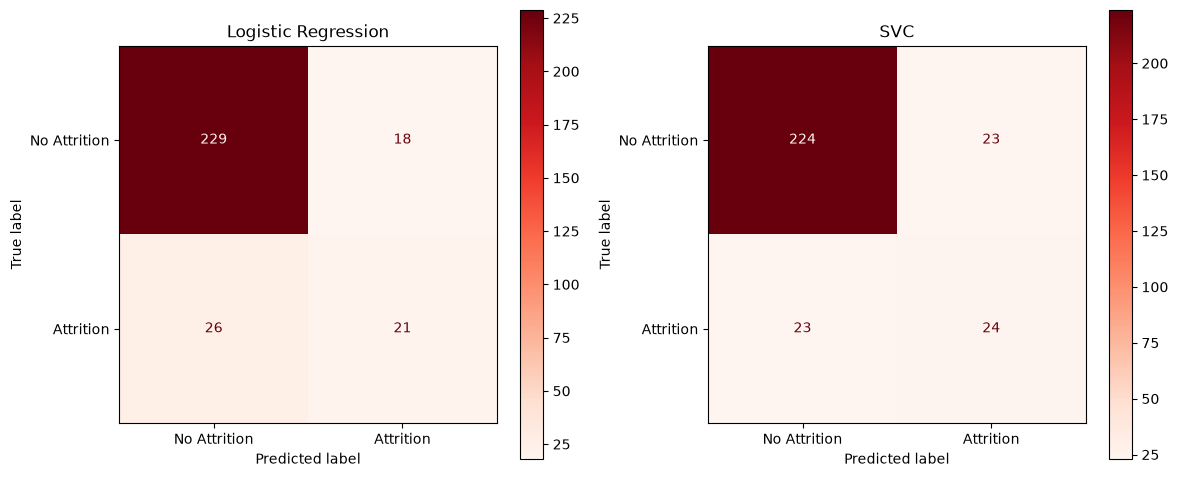

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(
    axes,
    [
        ('Logistic Regression', log_reg_tuned),
        ('SVC', svc_tuned)
    ]
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=['No Attrition', 'Attrition'],
        cmap='Reds',
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()